# T-Rex overview

Write the .instr file of T-Rex, with its default control parameters, to `mcstas_input/TRex/` of
the repository, print it, and plot the instrument with McStas's mcdisplay: seen from above, and
along the beam. The .instr file, both figures and an
interactive 3D view are saved for the documentation.

In [1]:
import shutil
from pathlib import Path
from unittest.mock import patch

import matplotlib.pyplot as plt
from ipywidgets.embed import embed_minimal_html

from mcdgs.instruments.trex.model import TRex
from mcdgs.mcstas.builder import build_mcstas, default_input_dir

# the repository: the first folder up from here that holds pyproject.toml
WORK_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
DOCS = WORK_DIR / "docs" / "instruments" / "trex"
DOCS_INSTR = DOCS / "files" / "TRex.instr"  # the copy the documentation shows
FIGURES = DOCS / "figures"
TOP_VIEW = FIGURES / "overview_top.png"
BEAM_VIEW = FIGURES / "overview_along_beam.png"
VIEW_3D = DOCS / "files" / "overview_3d.html"  # a web page, embedded in the documentation

## Create McStas model

In [2]:
trex = TRex()
mcstas_instr = build_mcstas(trex, input_path=default_input_dir(trex, WORK_DIR))
mcstas_instr.write_full_instrument()
mcstas_instr.show_instrument_file()

/********************************************************************************
* 
* McStas, neutron ray-tracing package
*         Copyright (C) 1997-2008, All rights reserved
*         Risoe National Laboratory, Roskilde, Denmark
*         Institut Laue Langevin, Grenoble, France
* 
* This file was written by McStasScript, which is a 
* python based McStas instrument generator written by 
* Mads Bertelsen in 2019 while employed at the 
* European Spallation Source Data Management and 
* Software Centre
* 
* Instrument: TRex
* 
* %Identification
* Written by: Python McStas Instrument Generator
* Date: 21:35:14 on November 03, 2026
* Origin: ESS DMSC
* %INSTRUMENT_SITE: Generated_instruments
* 
* !!Please write a short instrument description (1 line) here!!
* 
* %Description
* Please write a longer instrument description here!
* 
* 
* %Parameters
* bender_in: [unit] bender in = 1, out = 0
* b_rot: [unit] rotation of the cold neutron bender
* omega: [unit] rotation of the goniometer ab

## Generate the .instr file for doc

In [3]:
instr_file = Path(mcstas_instr.input_path) / f"{trex.name}.instr"
print(f"Written to {instr_file}")
DOCS_INSTR.parent.mkdir(exist_ok=True)
shutil.copyfile(instr_file, DOCS_INSTR)
print(f"Copied to {DOCS_INSTR}")

Written to /Users/bingli/Documents/GitHub/mcdgs/mcstas_input/TRex/TRex.instr
Copied to /Users/bingli/Documents/GitHub/mcdgs/docs/instruments/trex/files/TRex.instr


## Plot the layout of the instrument

Saved /Users/bingli/Documents/GitHub/mcdgs/docs/instruments/trex/figures/overview_top.png
Saved /Users/bingli/Documents/GitHub/mcdgs/docs/instruments/trex/figures/overview_along_beam.png


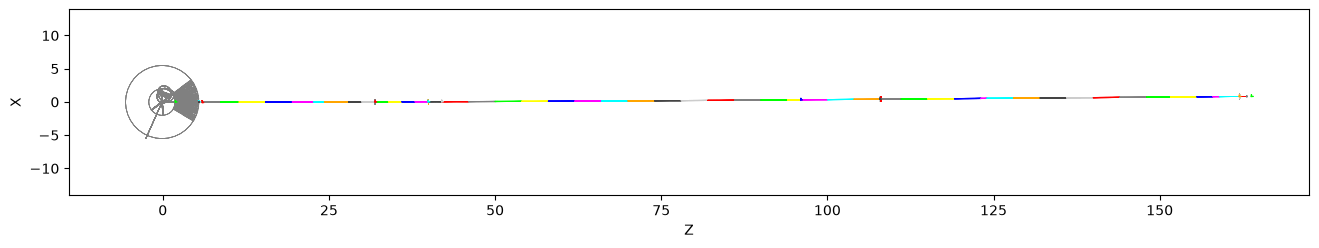

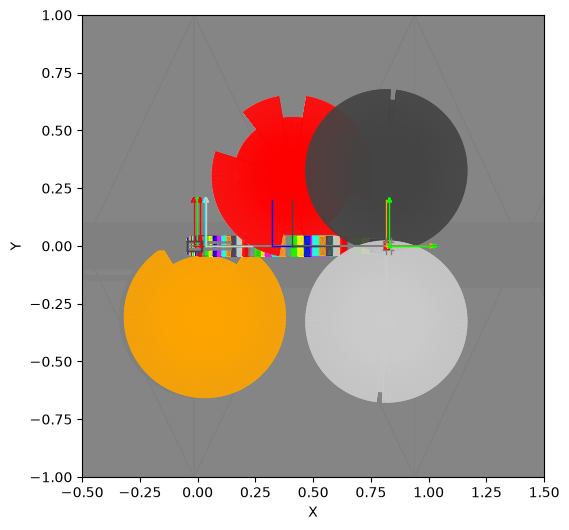

In [4]:
FIGURES.mkdir(exist_ok=True)
# z along the beam, x across it
# width and height are in pixels at 100 dpi: a figure of 16 x 4 in
with patch("matplotlib.pyplot.show"):
    mcstas_instr.show_instrument(backend="matplotlib_2d", projection="zx", width=1600, height=400)
# show_instrument returns None and has no aspect option: set it on the axes it drew
plt.gca().set_aspect("equal")
plt.gcf().savefig(TOP_VIEW, dpi=400)  # 6400 px wide, to zoom in on in the documentation
print(f"Saved {TOP_VIEW}")
# against beam, from detector to source
# limits are in m: [min, max] of the horizontal axis, then of the vertical one
with patch("matplotlib.pyplot.show"):
    mcstas_instr.show_instrument(
        backend="matplotlib_2d", projection="xy", limits=[-0.5, 1.5, -1, 1], width=600, height=600
    )
plt.gca().set_aspect("equal")
plt.gcf().savefig(BEAM_VIEW, dpi=150)
print(f"Saved {BEAM_VIEW}")

## 3D view

In [5]:
# 680 px wide: the width of the text column of the documentation
view = mcstas_instr.show_instrument(backend="pythreejs", width=680, height=480)
# the scene with its state, as a page that needs no kernel: it rotates and zooms, but the controls
# that call back into Python ("Take me to", the color mode, clicking a component) do nothing
embed_minimal_html(VIEW_3D, views=[view], title="T-Rex in 3D")
print(f"Saved {VIEW_3D}")
view